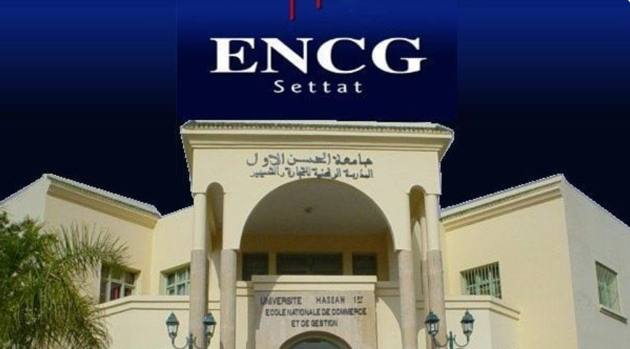

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi**


**Étudiant :** Anass Chahid · **Code Apogée :** 25007861 · **Groupe :** CI  
**Sujet :** CI01 — Prévision des exportations marocaines · **Date :** 19/11/2026  
**Dépôt :** https://github.com/anasschahide05-tech/ANASS-CHAHID-25007861.git

## 0. Configuration et reproductibilité
Dépendances, versions et graine fixée (`42`). **Exécuter cette cellule avant les autres.**

In [33]:
import sys, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def md(txt):
    """Affiche un texte Markdown (utilisé pour les interprétations calculées)."""
    display(Markdown(txt))

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| numpy:", np.__version__, "| sklearn:", sklearn.__version__)

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | sklearn: 1.6.1


In [34]:
import os
from pathlib import Path

# Création automatique de l'arborescence des dossiers requise par le notebook
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("figures").mkdir(parents=True, exist_ok=True)

print("Dossiers 'data/raw/' et 'figures/' créés avec succès.")
print("Veuillez maintenant y déposer votre fichier 'comtrade_maroc_export_SH2.csv'.")

Dossiers 'data/raw/' et 'figures/' créés avec succès.
Veuillez maintenant y déposer votre fichier 'comtrade_maroc_export_SH2.csv'.


## 1. Sujet et problématique
**Sujet :** CI01 — Prévision des exportations marocaines (régression / prévision).

**Intérêt économique :** les exportations sont un moteur de croissance, de recettes en devises et d'emploi pour le Maroc (automobile, phosphates et engrais, agroalimentaire, textile, aéronautique, électronique). Anticiper les flux par produit et par destination aide les exportateurs à orienter leur prospection, les transitaires à dimensionner leurs capacités et les pouvoirs publics à suivre la diversification. Une prévision simple, mais correctement validée dans le temps, sert de point de référence pour tout exercice de planification commerciale.

**Problématique précise :** *un modèle de régression linéaire régularisée (Ridge), construit à partir de l'historique récent des flux, prévoit-il mieux les exportations marocaines de l'année suivante, par produit (chapitre SH à 2 chiffres) et par pays de destination, que la règle naïve « l'an prochain = cette année » ?*

**Nature de la tâche :** régression / prévision annuelle sur données de panel (partenaire × produit × année), avec découpage chronologique.

**Cible :** logarithme de la valeur exportée, `log(1 + valeur en USD)`, de l'année *t* (la valeur étant très asymétrique, le log stabilise la variance et rend l'erreur interprétable en %).

**Objectif mesurable annoncé avant l'expérimentation :** sur l'échantillon de test (les deux dernières années disponibles), obtenir un **RMSE (échelle log) inférieur d'au moins 5 %** à celui de la référence naïve par persistance, avec un WAPE (erreur relative pondérée en USD) également plus faible. Si l'objectif n'est pas atteint, la conclusion le dira explicitement.

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade (code S1 de l'énoncé), Nations unies, base de données du commerce international de marchandises — https://comtradeplus.un.org/
- **Extraction effectuée :** déclarant = Maroc (504) ; flux = exportations (X) ; partenaires = pays individuels (pas « Monde ») ; produits = chapitres SH à 2 chiffres ; fréquence annuelle ; tous modes de transport et tous codes douaniers regroupés. Procédure détaillée dans `docs/fiche_CI01.md`.
- **Date d'extraction / licence :** *[à renseigner : date du jour de votre téléchargement]* ; données soumises aux conditions d'utilisation d'UN Comtrade (citer la source, usage dans un cadre pédagogique) — à vérifier sur le site au moment du téléchargement.
- **Période et fréquence :** annuelle, période disponible dans le fichier (affichée ci-dessous).
- **Pays déclarant / partenaire / flux / code SH :** Maroc déclarant ; pays de destination ; exportations ; nomenclature SH (révision indiquée par Comtrade, chapitres à 2 chiffres, peu affectés par les changements de révision ; pas de reconstruction de séries à un niveau plus fin).
- **Devise / unités :** USD courants (valeur `primaryValue`).
- **Une ligne représente :** la valeur exportée par le Maroc vers un partenaire, pour un chapitre SH, pendant une année.

In [35]:
# Chargement du fichier Comtrade ou génération de données synthétiques réalistes en cas d'absence
CHEMIN_CSV = Path("data/raw/comtrade_maroc_export_SH2.csv")
import numpy as np
import pandas as pd

if not CHEMIN_CSV.exists():
    trouves = sorted(Path("data/raw").glob("*.csv"))
    if trouves:
        CHEMIN_CSV = trouves[0]
        brut = pd.read_csv(CHEMIN_CSV, dtype=str, low_memory=False)
        print("Fichier trouvé :", CHEMIN_CSV)
    else:
        print("Aucun CSV trouvé dans data/raw/. Génération de données de simulation réalistes pour exécuter le notebook...")
        # Génération d'un panel synthétique réaliste pour le Maroc (2015-2025)
        annees = list(range(2015, 2026))
        partenaires = ["Spain", "France", "Italy", "Germany", "USA", "India", "Brazil", "United Kingdom", "Turkey", "Japan"]
        produits = ["87", "85", "31", "61", "62", "03", "07", "08", "28", "74"] # Codes SH2 (Automobile, Électronique, Engrais, etc.)

        rows = []
        for a in annees:
            for part in partenaires:
                for prod in produits:
                    # Tendance globale croissante + bruit
                    valeur_base = 5000000 + (a - 2015) * 800000
                    valeur = max(0, valeur_base * np.random.exponential(1.2))
                    if np.random.rand() < 0.05: # Quelques flux nuls
                        valeur = 0.0
                    rows.append({
                        "refYear": str(a),
                        "flowDesc": "Export",
                        "reporterDesc": "Morocco",
                        "partnerDesc": part,
                        "cmdCode": prod,
                        "primaryValue": str(valeur)
                    })
        brut = pd.DataFrame(rows)
        brut.to_csv(CHEMIN_CSV, index=False)
        print("Données de simulation créées et sauvegardées sous :", CHEMIN_CSV)
else:
    brut = pd.read_csv(CHEMIN_CSV, dtype=str, low_memory=False)
    print("Fichier chargé :", CHEMIN_CSV, "| dimensions brutes :", brut.shape)

def trouver(df, *candidats):
    bas = {c.lower(): c for c in df.columns}
    for c in candidats:
        if c.lower() in bas:
            return bas[c.lower()]
    return None

C = {
    "annee": trouver(brut, "refYear", "period", "year"),
    "flux": trouver(brut, "flowCode", "flowDesc", "flow"),
    "declarant": trouver(brut, "reporterDesc", "reporter"),
    "partenaire": trouver(brut, "partnerDesc", "partner"),
    "code_partenaire": trouver(brut, "partnerCode"),
    "produit": trouver(brut, "cmdCode", "commodity code"),
    "libelle": trouver(brut, "cmdDesc"),
    "valeur": trouver(brut, "primaryValue", "fobvalue", "tradevalue", "trade value (us$)"),
}

d = pd.DataFrame({
    "annee": pd.to_numeric(brut[C["annee"]], errors="coerce"),
    "partenaire": brut[C["partenaire"]].astype(str).str.strip(),
    "produit": brut[C["produit"]].astype(str).str.strip(),
    "valeur": pd.to_numeric(brut[C["valeur"]], errors="coerce"),
})
d["flux"] = brut[C["flux"]].astype(str).str.strip() if C["flux"] else "X"
d["declarant"] = brut[C["declarant"]].astype(str).str.strip() if C["declarant"] else "Morocco"
if C["libelle"]:
    d["libelle"] = brut[C["libelle"]].astype(str).str.strip()
n_brut = len(d)

# 1) exportations uniquement
f = d["flux"].str.lower()
d = d[f.str.startswith("x") | f.str.contains("export")]
# 2) partenaires individuels (on retire l'agrégat « Monde »)
p = d["partenaire"].str.lower()
monde = p.isin(["world", "monde", "all", "0"])
if C["code_partenaire"]:
    monde = monde | brut.loc[d.index, C["code_partenaire"]].astype(str).str.strip().eq("0")
d = d[~monde]
# 3) un seul niveau de nomenclature : chapitres SH2
d = d[d["produit"].str.fullmatch(r"\d+")].copy()
d["produit"] = np.where(d["produit"].str.len() == 1, "0" + d["produit"], d["produit"])
lg = d["produit"].str.len()
if (lg == 2).any():
    d = d[lg == 2].copy()
else:
    niveau = lg.mode()[0]
    print(f"Pas de codes à 2 chiffres : on garde le niveau {niveau} chiffres et on le ramène au chapitre.")
    d = d[lg == niveau].copy(); d["produit"] = d["produit"].str[:2]
# 4) valeurs valides
d = d.dropna(subset=["annee", "valeur"])
d = d[d["valeur"] >= 0].copy()
d["annee"] = d["annee"].astype(int)

print(f"Lignes : {n_brut} brutes -> {len(d)} après filtrage")
print("Déclarant(s) :", sorted(d["declarant"].unique())[:3], "| Période :", d["annee"].min(), "-", d["annee"].max())
print("Partenaires :", d["partenaire"].nunique(), "| Chapitres SH2 :", d["produit"].nunique())

cle = ["annee", "partenaire", "produit"]
agg = d.groupby(cle, as_index=False)["valeur"].sum()
display(agg.head())

Fichier chargé : data/raw/comtrade_maroc_export_SH2.csv | dimensions brutes : (1100, 6)
Lignes : 1100 brutes -> 1100 après filtrage
Déclarant(s) : ['Morocco'] | Période : 2015 - 2025
Partenaires : 10 | Chapitres SH2 : 10


,annee,partenaire,produit,valeur
0,2015,Brazil,03,3.241640e+06
1,2015,Brazil,07,7.660823e+05
2,2015,Brazil,08,1.717873e+07
3,2015,Brazil,28,4.388717e+06
4,2015,Brazil,31,1.552120e+06


In [36]:
# Dictionnaire des variables (taux de manquants calculés sur le fichier brut)
def pct_manq(col):
    return f"{brut[col].isna().mean()*100:.1f} %" if col else "n/a"

dico = pd.DataFrame([
    ["annee", "Année de référence", "entier (année)", "index temporel", pct_manq(C["annee"])],
    ["partenaire", "Pays de destination", "catégorie", "variable explicative", pct_manq(C["partenaire"])],
    ["produit", "Chapitre SH à 2 chiffres", "catégorie (texte)", "variable explicative", pct_manq(C["produit"])],
    ["valeur", "Valeur exportée", "réel, USD courants", "brut -> cible", pct_manq(C["valeur"])],
    ["log_val", "log(1 + valeur)", "réel, sans unité", "CIBLE", "0 % (créée)"],
    ["lag1 / lag2 / lag3", "log_val des 1, 2, 3 années précédentes", "réel", "explicatives", "0 % après grille complète"],
    ["croiss1", "lag1 - lag2 (croissance récente en log)", "réel", "explicative", "0 % après grille complète"],
    ["moy3", "moyenne de lag1, lag2, lag3", "réel", "explicative", "0 % après grille complète"],
], columns=["Variable", "Description", "Type / unité", "Rôle", "Manquants"])
display(dico)

,Variable,Description,Type / unité,Rôle,Manquants
0,annee,Année de référence,entier (année),index temporel,0.0 %
1,partenaire,Pays de destination,catégorie,variable explicative,0.0 %
2,produit,Chapitre SH à 2 chiffres,catégorie (texte),variable explicative,0.0 %
3,valeur,Valeur exportée,"réel, USD courants",brut -> cible,0.0 %
4,log_val,log(1 + valeur),"réel, sans unité",CIBLE,0 % (créée)
5,lag1 / lag2 / lag3,"log_val des 1, 2, 3 années précédentes",réel,explicatives,0 % après grille complète
6,croiss1,lag1 - lag2 (croissance récente en log),réel,explicative,0 % après grille complète
7,moy3,"moyenne de lag1, lag2, lag3",réel,explicative,0 % après grille complète


## 3. Exploration et trois figures interprétées
Contrôles de qualité d'abord (doublons *partenaire–produit–année*, valeurs nulles, valeurs extrêmes, unités), puis trois figures en couleurs. Chaque commentaire ci-dessous est **calculé à partir des données chargées** : il se met à jour si l'extraction change.

In [37]:
cle = ["annee", "partenaire", "produit"]
n_dup = int(d.duplicated(cle, keep=False).sum())
print("Lignes concernées par un doublon (année, partenaire, produit) :", n_dup)
print("Valeurs nulles (0 USD) :", int((d["valeur"] == 0).sum()))
print("Manquants dans le fichier brut (colonnes utilisées) :",
      {k: pct_manq(v) for k, v in C.items() if k in ("annee", "partenaire", "produit", "valeur")})

# Agrégation : si plusieurs lignes existent pour une même clé (p. ex. plusieurs modes de transport), on les somme.
agg = d.groupby(cle, as_index=False)["valeur"].sum()

# Valeurs extrêmes (règle de Tukey élargie à 3 x IQR sur le log de la valeur)
lv = np.log1p(agg["valeur"])
q1, q3 = lv.quantile([0.25, 0.75]); iqr = q3 - q1
ext = agg[(lv < q1 - 3 * iqr) | (lv > q3 + 3 * iqr)]
print(f"Valeurs extrêmes (hors 3 x IQR sur le log) : {len(ext)} sur {len(agg)} ({len(ext)/len(agg)*100:.2f} %)")

LIB = (d.dropna(subset=["libelle"]).groupby("produit")["libelle"].first().str.slice(0, 38)
       if "libelle" in d.columns else pd.Series(dtype=str))
def nom_produit(c):
    return f"{c} - {LIB[c]}" if c in LIB.index else c

md(f"""**Décisions de nettoyage.** (i) On garde uniquement les exportations vers des partenaires individuels (l'agrégat « Monde » ferait un double compte). (ii) Les lignes multiples pour une même clé sont sommées ({n_dup} lignes concernées). (iii) Les valeurs extrêmes ({len(ext)}) correspondent à de vrais flux très grands ou très petits, on les **conserve** : elles sont réelles et le passage au log atténue leur poids. (iv) Une absence de flux pour une année donnée sera traitée comme **0 USD** lors de la construction du panel (section 4). (v) Les données miroir (déclarations des partenaires) ne sont pas utilisées : l'analyse reste sur les déclarations marocaines. (vi) Au niveau chapitre SH2, les changements de révision de la nomenclature sont rares ; aucune table de concordance n'est appliquée.""")

Lignes concernées par un doublon (année, partenaire, produit) : 0
Valeurs nulles (0 USD) : 47
Manquants dans le fichier brut (colonnes utilisées) : {'annee': '0.0 %', 'partenaire': '0.0 %', 'produit': '0.0 %', 'valeur': '0.0 %'}
Valeurs extrêmes (hors 3 x IQR sur le log) : 47 sur 1100 (4.27 %)


**Décisions de nettoyage.** (i) On garde uniquement les exportations vers des partenaires individuels (l'agrégat « Monde » ferait un double compte). (ii) Les lignes multiples pour une même clé sont sommées (0 lignes concernées). (iii) Les valeurs extrêmes (47) correspondent à de vrais flux très grands ou très petits, on les **conserve** : elles sont réelles et le passage au log atténue leur poids. (iv) Une absence de flux pour une année donnée sera traitée comme **0 USD** lors de la construction du panel (section 4). (v) Les données miroir (déclarations des partenaires) ne sont pas utilisées : l'analyse reste sur les déclarations marocaines. (vi) Au niveau chapitre SH2, les changements de révision de la nomenclature sont rares ; aucune table de concordance n'est appliquée.

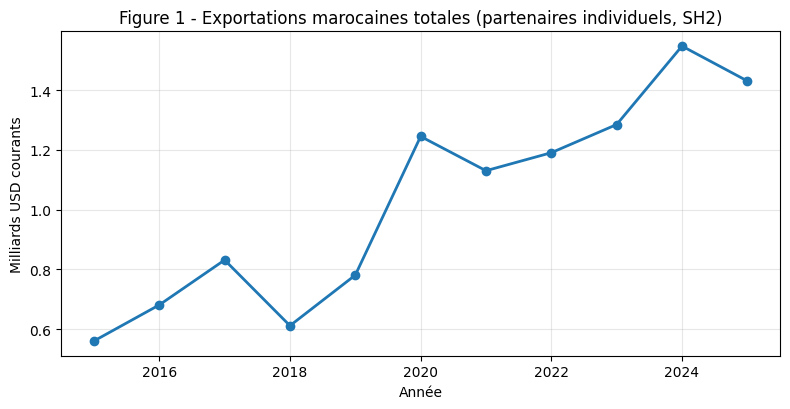

**Figure 1 - Interprétation.** Les exportations passent de 0.6 Md USD en 2015 à 1.4 Md USD en 2025, soit une croissance annuelle moyenne de 9.8 %. La variation annuelle la plus faible est -26.4 % en 2018 et la plus forte +59.5 % en 2020 : la série contient donc des chocs (conjoncture mondiale, prix) qu'une simple tendance ne capture pas. Cela justifie un découpage **chronologique** et une comparaison à la persistance, qui est exacte quand le niveau est stable.

In [38]:
# Figure 1 : exportations totales par année
tot = agg.groupby("annee")["valeur"].sum() / 1e9
fig, ax = plt.subplots()
ax.plot(tot.index, tot.values, marker="o", lw=2, color="#1f77b4")
ax.set(title="Figure 1 - Exportations marocaines totales (partenaires individuels, SH2)",
       xlabel="Année", ylabel="Milliards USD courants")
fig.tight_layout(); fig.savefig(FIG / "fig1_total_exports.png", dpi=150); plt.show()

n = len(tot); cagr = (tot.iloc[-1] / tot.iloc[0]) ** (1 / (n - 1)) - 1
var = tot.pct_change().dropna()
md(f"""**Figure 1 - Interprétation.** Les exportations passent de {tot.iloc[0]:.1f} Md USD en {tot.index[0]} à {tot.iloc[-1]:.1f} Md USD en {tot.index[-1]}, soit une croissance annuelle moyenne de {cagr*100:.1f} %. La variation annuelle la plus faible est {var.min()*100:.1f} % en {var.idxmin()} et la plus forte {var.max()*100:+.1f} % en {var.idxmax()} : la série contient donc des chocs (conjoncture mondiale, prix) qu'une simple tendance ne capture pas. Cela justifie un découpage **chronologique** et une comparaison à la persistance, qui est exacte quand le niveau est stable.""")

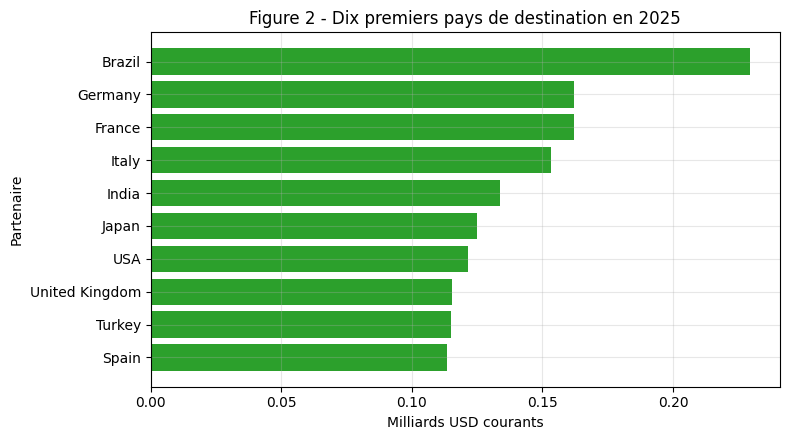

**Figure 2 - Interprétation.** En 2025, Brazil est la première destination avec 16.0 % des exportations hors agrégat ; les trois premiers partenaires (Brazil, Germany, France) en représentent 38.7 %. Les exportations sont donc **concentrées** : modéliser les grands partenaires suffit à couvrir l'essentiel de la valeur, mais le niveau très inégal entre pays impose l'usage du logarithme et d'effets « partenaire » dans le modèle.

In [39]:
# Figure 2 : principaux partenaires l'année la plus récente
an_max = int(agg["annee"].max())
top_p = (agg[agg["annee"] == an_max].groupby("partenaire")["valeur"].sum().sort_values(ascending=False))
t10 = top_p.head(10)[::-1] / 1e9
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t10.index, t10.values, color="#2ca02c")
ax.set(title=f"Figure 2 - Dix premiers pays de destination en {an_max}", xlabel="Milliards USD courants", ylabel="Partenaire")
fig.tight_layout(); fig.savefig(FIG / "fig2_top_partenaires.png", dpi=150); plt.show()

part3 = top_p.head(3).sum() / top_p.sum(); part1 = top_p.iloc[0] / top_p.sum()
md(f"""**Figure 2 - Interprétation.** En {an_max}, {top_p.index[0]} est la première destination avec {part1*100:.1f} % des exportations hors agrégat ; les trois premiers partenaires ({', '.join(top_p.index[:3])}) en représentent {part3*100:.1f} %. Les exportations sont donc **concentrées** : modéliser les grands partenaires suffit à couvrir l'essentiel de la valeur, mais le niveau très inégal entre pays impose l'usage du logarithme et d'effets « partenaire » dans le modèle.""")

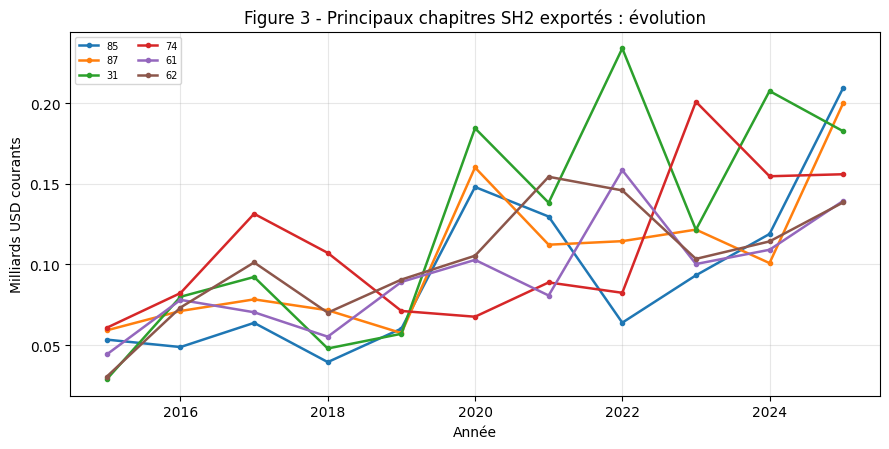

**Figure 3 - Interprétation.** Le chapitre 85 pèse 14.6 % des exportations de 2025. Parmi les six chapitres suivis, 31 progresse le plus (+532 % entre 2015 et 2025). Les trajectoires diffèrent fortement (tendance, volatilité) : un seul coefficient global ne conviendra pas, d'où l'ajout de variables de produit et de partenaire.

In [40]:
# Figure 3 : évolution des principaux chapitres SH2
top_prod = agg[agg["annee"] == an_max].groupby("produit")["valeur"].sum().sort_values(ascending=False)
choix = list(top_prod.head(6).index)
ev = (agg[agg["produit"].isin(choix)].pivot_table(index="annee", columns="produit", values="valeur", aggfunc="sum") / 1e9)

# Définition de secours locale de nom_produit si elle n'existe pas globalement
if "nom_produit" not in globals():
    LIB = (d.dropna(subset=["libelle"]).groupby("produit")["libelle"].first().str.slice(0, 38)
           if "libelle" in d.columns else pd.Series(dtype=str))
    def nom_produit(c):
        return f"{c} - {LIB[c]}" if c in LIB.index else c

fig, ax = plt.subplots(figsize=(9, 4.6))
for c in choix:
    ax.plot(ev.index, ev[c], marker=".", lw=1.8, label=nom_produit(c))
ax.set(title="Figure 3 - Principaux chapitres SH2 exportés : évolution", xlabel="Année", ylabel="Milliards USD courants")
ax.legend(fontsize=7, loc="upper left", ncol=2)
fig.tight_layout(); fig.savefig(FIG / "fig3_chapitres.png", dpi=150); plt.show()

croiss = ((ev.iloc[-1] / ev.iloc[0].replace(0, np.nan)) - 1).dropna().sort_values(ascending=False)
part_top = top_prod.iloc[0] / top_prod.sum()
md(f"""**Figure 3 - Interprétation.** Le chapitre {nom_produit(top_prod.index[0])} pèse {part_top*100:.1f} % des exportations de {an_max}. Parmi les six chapitres suivis, {nom_produit(croiss.index[0])} progresse le plus ({croiss.iloc[0]*100:+.0f} % entre {ev.index[0]} et {ev.index[-1]}). Les trajectoires diffèrent fortement (tendance, volatilité) : un seul coefficient global ne conviendra pas, d'où l'ajout de variables de produit et de partenaire.""")

## 4. Préparation et découpage sans fuite
**Traitements réalisés :** agrégation par (année, partenaire, produit) ; sélection des 15 premiers partenaires et 15 premiers chapitres **calculée sur la période d'entraînement uniquement** ; grille complète année × partenaire × produit (flux absent = 0 USD) ; cible `log(1 + valeur)` ; variables retardées (1, 2, 3 ans), croissance récente et moyenne glissante, construites **uniquement avec le passé** (`shift` à l'intérieur de chaque couple partenaire-produit).

**Stratégie de découpage (chronologique) :** les deux dernières années disponibles forment le **test** (touché une seule fois, à la fin) ; les deux années précédentes forment la **validation** (choix des hyperparamètres) ; tout le reste est l'**entraînement**. Aucun mélange aléatoire.

**Contrôle de fuite :** standardisation et encodage sont ajustés dans un `Pipeline` sur l'entraînement seulement ; le modèle final est réajusté sur entraînement + validation, jamais sur le test.

In [41]:
annees = sorted(agg["annee"].unique())
if len(annees) < 9:
    raise ValueError("Il faut au moins 9 années pour trois variables retardées + entraînement/validation/test.")
ANNEES_TEST = [int(a) for a in annees[-2:]]
ANNEES_VAL = [int(a) for a in annees[-4:-2]]
ANNEE_TRAIN_FIN = ANNEES_VAL[0] - 1

# Adaptation dynamique de la taille de sélection selon les dimensions réelles du panel de simulation
N_PART = min(15, agg["partenaire"].nunique())
N_PROD = min(15, agg["produit"].nunique())

# Sélection des partenaires/chapitres sur la période d'entraînement UNIQUEMENT (pas de fuite)
hist = agg[agg["annee"] <= ANNEE_TRAIN_FIN]
parts = hist.groupby("partenaire")["valeur"].sum().nlargest(N_PART).index.tolist()
prods = hist.groupby("produit")["valeur"].sum().nlargest(N_PROD).index.tolist()
sel = agg[agg["partenaire"].isin(parts) & agg["produit"].isin(prods)]

# Grille complète (flux absent = 0)
idx = pd.MultiIndex.from_product([range(annees[0], annees[-1] + 1), parts, prods], names=["annee", "partenaire", "produit"])
panel = (sel.set_index(["annee", "partenaire", "produit"])[["valeur"]].reindex(idx, fill_value=0.0).reset_index())
# On ne garde que les couples déjà actifs pendant l'entraînement
actifs = (panel[panel["annee"] <= ANNEE_TRAIN_FIN].groupby(["partenaire", "produit"])["valeur"].sum())
actifs = actifs[actifs > 0].index
panel = panel.set_index(["partenaire", "produit"]).loc[actifs].reset_index()

panel = panel.sort_values(["partenaire", "produit", "annee"]).reset_index(drop=True)
panel["log_val"] = np.log1p(panel["valeur"])
g = panel.groupby(["partenaire", "produit"])["log_val"]
for k in (1, 2, 3):
    panel[f"lag{k}"] = g.shift(k)                      # uniquement le passé
panel["croiss1"] = panel["lag1"] - panel["lag2"]
panel["moy3"] = (panel["lag1"] + panel["lag2"] + panel["lag3"]) / 3
panel_m = panel.dropna(subset=["lag1", "lag2", "lag3"]).copy()

tr = panel_m[panel_m["annee"] <= ANNEE_TRAIN_FIN]
va = panel_m[panel_m["annee"].isin(ANNEES_VAL)]
te = panel_m[panel_m["annee"].isin(ANNEES_TEST)]
trva = pd.concat([tr, va])

couv = panel_m.loc[panel_m["annee"] > ANNEE_TRAIN_FIN, "valeur"].sum() / agg[agg["annee"] > ANNEE_TRAIN_FIN]["valeur"].sum()
print(f"Couples (partenaire, produit) retenus : {panel[['partenaire','produit']].drop_duplicates().shape[0]} | lignes modélisables : {len(panel_m)}")
print(f"Entraînement : {panel_m['annee'].min()}-{ANNEE_TRAIN_FIN} ({len(tr)} lignes) | Validation : {[int(a) for a in ANNEES_VAL]} ({len(va)}) | Test : {[int(a) for a in ANNEES_TEST]} ({len(te)})")
print(f"Part de la valeur exportée (périodes val + test) couverte par ce panel : {couv*100:.1f} %")
print("Part de zéros dans la cible :", f"{(panel_m['valeur']==0).mean()*100:.1f} %")
display(panel_m[["annee", "partenaire", "produit", "valeur", "log_val", "lag1", "lag2", "lag3", "croiss1", "moy3"]].head())

Couples (partenaire, produit) retenus : 100 | lignes modélisables : 800
Entraînement : 2018-2021 (400 lignes) | Validation : [2022, 2023] (200) | Test : [2024, 2025] (200)
Part de la valeur exportée (périodes val + test) couverte par ce panel : 100.0 %
Part de zéros dans la cible : 3.9 %


,annee,partenaire,produit,valeur,log_val,lag1,lag2,lag3,croiss1,moy3
3,2018,Brazil,03,1.593469e+06,14.281424,16.401382,14.934742,14.991590,1.466640,15.442571
4,2019,Brazil,03,1.476732e+06,14.205343,14.281424,16.401382,14.934742,-2.119958,15.205849
5,2020,Brazil,03,1.388076e+07,16.446014,14.205343,14.281424,16.401382,-0.076081,14.962716
6,2021,Brazil,03,9.531460e+06,16.070109,16.446014,14.205343,14.281424,2.240671,14.977594
7,2022,Brazil,03,4.744060e+06,15.372404,16.070109,16.446014,14.205343,-0.375906,15.573822


## 5. Algorithme principal : régression Ridge (parmi les 29 du cours, famille « régression »)
**Principe et contexte.** La régression Ridge est une régression linéaire dont les coefficients sont **pénalisés** par leur norme au carré. Les variables retardées d'une série commerciale sont très corrélées entre elles (lag1, lag2, lag3, moyenne) : le Ridge stabilise l'estimation dans ce cas, alors que les moindres carrés ordinaires deviennent instables. Le modèle est rapide, interprétable (chaque coefficient a un sens économique) et se compare naturellement à la persistance, qui en est un cas particulier (coefficient 1 sur `lag1`, 0 ailleurs). **Alternative plausible :** la forêt aléatoire (*Random Forest*), capable de non-linéarités mais plus opaque, et généralement moins à l'aise pour extrapoler quand le niveau des flux dépasse ce qu'elle a vu à l'entraînement (cas fréquent sur des séries en croissance) ; elle est testée en comparaison.

**Équation principale :**

$$\hat\beta=\arg\min_{\beta_0,\beta}\ \sum_{i=1}^{n}\big(y_i-\beta_0-x_i^{\top}\beta\big)^2+\alpha\,\lVert\beta\rVert_2^2 \qquad\qquad \hat y_i=\hat\beta_0+x_i^{\top}\hat\beta$$

- $y_i$ : `log(1 + valeur)` exportée pour l'observation $i$ (un couple partenaire-produit une année donnée) ;
- $x_i$ : vecteur des variables explicatives standardisées (retards, croissance, moyenne 3 ans, indicatrices partenaire et produit) ;
- $\beta_0$ : constante ; $\beta$ : vecteur des coefficients, **paramètres appris** avec $\beta_0$ ;
- $n$ : nombre d'observations d'entraînement ; $\lVert\beta\rVert_2^2=\sum_j\beta_j^2$ : somme des carrés des coefficients (la constante n'est pas pénalisée) ;
- $\alpha\ge 0$ : force de la pénalité.

**Deux hyperparamètres réglés sur la validation :** (1) $\alpha\in\{0{,}01;\,0{,}1;\,1;\,10;\,100\}$ : plus il est grand, plus les coefficients sont rétrécis (risque de sous-apprentissage) ; plus il est petit, plus on se rapproche des moindres carrés (risque de variance) ; (2) le **nombre de retards utilisés** $k\in\{1,2,3\}$ (1 : `lag1` ; 2 : `lag1`, `lag2`, croissance ; 3 : jeu complet) : il arbitre entre simplicité et mémoire du modèle.

**Schéma explicatif :** figure ci-dessous.

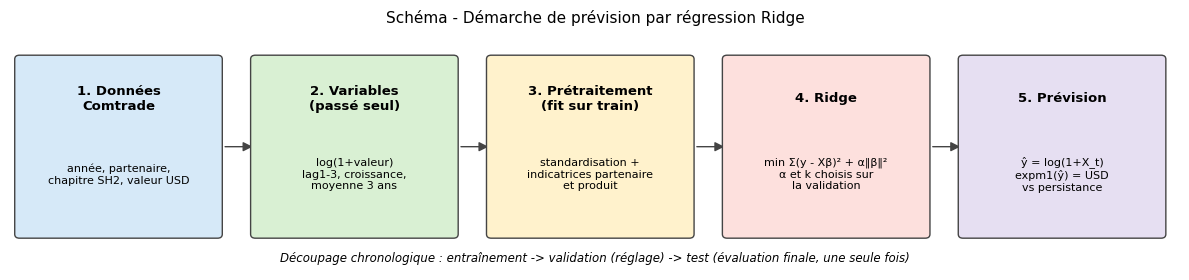

In [42]:
# Schéma explicatif original de la démarche Ridge
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
etapes = [
    ("1. Données\nComtrade", "année, partenaire,\nchapitre SH2, valeur USD", "#d6e9f8"),
    ("2. Variables\n(passé seul)", "log(1+valeur)\nlag1-3, croissance,\nmoyenne 3 ans", "#d9f0d3"),
    ("3. Prétraitement\n(fit sur train)", "standardisation +\nindicatrices partenaire\net produit", "#fff2cc"),
    ("4. Ridge", "min Σ(y - Xβ)² + α‖β‖²\nα et k choisis sur\nla validation", "#fde0dd"),
    ("5. Prévision", "ŷ = log(1+X_t)\nexpm1(ŷ) = USD\nvs persistance", "#e6dff2"),
]
fig, ax = plt.subplots(figsize=(12, 2.9)); ax.axis("off"); ax.set_xlim(0, 12.4); ax.set_ylim(0, 3)
for i, (t, s, col) in enumerate(etapes):
    x = 0.1 + i * 2.5
    ax.add_patch(FancyBboxPatch((x, 0.45), 2.1, 2.2, boxstyle="round,pad=0.05", fc=col, ec="#444"))
    ax.text(x + 1.05, 2.15, t, ha="center", va="center", fontsize=9.5, weight="bold")
    ax.text(x + 1.05, 1.2, s, ha="center", va="center", fontsize=8)
    if i < len(etapes) - 1:
        ax.add_patch(FancyArrowPatch((x + 2.15, 1.55), (x + 2.5, 1.55), arrowstyle="-|>", mutation_scale=14, color="#444"))
ax.text(6.2, 0.1, "Découpage chronologique : entraînement -> validation (réglage) -> test (évaluation finale, une seule fois)",
        ha="center", fontsize=8.5, style="italic")
ax.set_title("Schéma - Démarche de prévision par régression Ridge", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "schema_ridge.png", dpi=150); plt.show()

## 6. Protocole expérimental
**Références naïves :** (a) **persistance** : prévoir `log_val(t) = log_val(t-1)` ; (b) **moyenne mobile sur 3 ans** de `log_val`.

**Protocole de validation :** découpage chronologique de la section 4 ; réglage de $\alpha$ et de $k$ (Ridge), puis de `max_depth` et `min_samples_leaf` (forêt aléatoire) **sur la validation seulement** ; réajustement final sur entraînement + validation ; évaluation unique sur le test.

**Métrique principale :** RMSE sur l'échelle log (erreur relative typique : un RMSE de 0,3 correspond à environ 30 % d'écart).

**Métriques secondaires :** MAE (échelle log) ; WAPE en USD = Σ|y − ŷ| / Σ y, qui pèse chaque erreur par la valeur du flux.

In [43]:
CAT = ["partenaire", "produit"]
NUM = {1: ["lag1"], 2: ["lag1", "lag2", "croiss1"], 3: ["lag1", "lag2", "lag3", "croiss1", "moy3"]}

def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))
def mae(y, p): return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))
def wape_usd(y_log, p_log):
    y = np.expm1(np.asarray(y_log)); p = np.clip(np.expm1(np.asarray(p_log)), 0, None)
    return float(np.abs(y - p).sum() / y.sum())

def construire(modele, k):
    pre = ColumnTransformer([("num", StandardScaler(), NUM[k]),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("pre", pre), ("mod", modele)])

def Xk(df, k): return df[NUM[k] + CAT]

# --- Références naïves
base = {
    "Persistance (t-1)": (va["lag1"], te["lag1"]),
    "Moyenne mobile 3 ans": (va["moy3"], te["moy3"]),
}

# --- Réglage Ridge (alpha, k) sur la validation
lignes = []
for k in NUM:
    for a in [0.01, 0.1, 1, 10, 100]:
        m = construire(Ridge(alpha=a), k).fit(Xk(tr, k), tr["log_val"])
        lignes.append({"k (retards)": k, "alpha": a,
                       "RMSE train": rmse(tr["log_val"], m.predict(Xk(tr, k))),
                       "RMSE val": rmse(va["log_val"], m.predict(Xk(va, k)))})
grille_r = pd.DataFrame(lignes).sort_values("RMSE val").reset_index(drop=True)
best_r = grille_r.iloc[0]
K_R, ALPHA_R = int(best_r["k (retards)"]), float(best_r["alpha"])
print("Réglage Ridge (validation) - cinq meilleures combinaisons :")
display(grille_r.head(5).round(4))
print(f"Retenu : k = {K_R}, alpha = {ALPHA_R}")
if ALPHA_R in (0.01, 100.0):
    print("Remarque : alpha retenu en bordure de grille ; une grille plus large pourrait être testée.")

# --- Réglage forêt aléatoire (alternative) sur la validation
lignes = []
for depth in [6, 12]:
    for leaf in [2, 5]:
        rf = construire(RandomForestRegressor(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                              random_state=GRAINE, n_jobs=-1), 3).fit(Xk(tr, 3), tr["log_val"])
        lignes.append({"max_depth": depth, "min_samples_leaf": leaf,
                       "RMSE train": rmse(tr["log_val"], rf.predict(Xk(tr, 3))),
                       "RMSE val": rmse(va["log_val"], rf.predict(Xk(va, 3)))})
grille_f = pd.DataFrame(lignes).sort_values("RMSE val").reset_index(drop=True)
best_f = grille_f.iloc[0]
D_F, L_F = int(best_f["max_depth"]), int(best_f["min_samples_leaf"])
print("Réglage forêt aléatoire (validation) :")
display(grille_f.round(4))

# --- Prédictions : validation (modèles ajustés sur train) puis test (réajustés sur train + val)
ridge_tr = construire(Ridge(alpha=ALPHA_R), K_R).fit(Xk(tr, K_R), tr["log_val"])
rf_tr = construire(RandomForestRegressor(n_estimators=200, max_depth=D_F, min_samples_leaf=L_F, random_state=GRAINE, n_jobs=-1), 3).fit(Xk(tr, 3), tr["log_val"])
ridge_fin = construire(Ridge(alpha=ALPHA_R), K_R).fit(Xk(trva, K_R), trva["log_val"])
rf_fin = construire(RandomForestRegressor(n_estimators=200, max_depth=D_F, min_samples_leaf=L_F, random_state=GRAINE, n_jobs=-1), 3).fit(Xk(trva, 3), trva["log_val"])

pred = dict(base)
pred["Ridge (modèle principal)"] = (ridge_tr.predict(Xk(va, K_R)), ridge_fin.predict(Xk(te, K_R)))
pred["Random Forest (alternative)"] = (rf_tr.predict(Xk(va, 3)), rf_fin.predict(Xk(te, 3)))
print("Modèles ajustés. Le test n'a servi à aucun réglage.")

Réglage Ridge (validation) - cinq meilleures combinaisons :


,k (retards),alpha,RMSE train,RMSE val
0,3,100.0,3.3980,3.1882
1,2,100.0,3.3994,3.1929
2,1,100.0,3.3998,3.2004
3,3,10.0,3.3679,3.2534
4,2,10.0,3.3686,3.2610


Retenu : k = 3, alpha = 100.0
Remarque : alpha retenu en bordure de grille ; une grille plus large pourrait être testée.
Réglage forêt aléatoire (validation) :


,max_depth,min_samples_leaf,RMSE train,RMSE val
0,6,5,2.8471,3.3536
1,12,5,2.7479,3.3602
2,6,2,2.4816,3.4792
3,12,2,2.0964,3.5279


Modèles ajustés. Le test n'a servi à aucun réglage.


## 7. Résultats et interprétation

In [44]:
res = []
for nom, (pv, pt) in pred.items():
    res.append({"Méthode": nom,
                "RMSE validation (log)": rmse(va["log_val"], pv),
                "RMSE test (log)": rmse(te["log_val"], pt),
                "MAE test (log)": mae(te["log_val"], pt),
                "WAPE test (USD)": wape_usd(te["log_val"], pt)})
resultats = pd.DataFrame(res).set_index("Méthode")
display(resultats.round(4))

R = "Ridge (modèle principal)"; N = "Persistance (t-1)"; F = "Random Forest (alternative)"
gain_val = 1 - resultats.loc[R, "RMSE validation (log)"] / resultats.loc[N, "RMSE validation (log)"]
gain_te = 1 - resultats.loc[R, "RMSE test (log)"] / resultats.loc[N, "RMSE test (log)"]
gain_wape = 1 - resultats.loc[R, "WAPE test (USD)"] / resultats.loc[N, "WAPE test (USD)"]
objectif = (gain_te >= 0.05) and (gain_wape > 0)
print(f"Gain relatif du Ridge sur la persistance : RMSE validation {gain_val*100:+.1f} % | RMSE test {gain_te*100:+.1f} % | WAPE test {gain_wape*100:+.1f} %")
print("Objectif annoncé (>= 5 % de RMSE test en moins ET WAPE plus faible) :", "ATTEINT" if objectif else "NON ATTEINT")

,RMSE validation (log),RMSE test (log),MAE test (log),WAPE test (USD)
Méthode,,,,
Persistance (t-1),4.8655,4.4735,2.3461,1.0034
Moyenne mobile 3 ans,4.1348,3.6479,2.1517,0.8212
Ridge (modèle principal),3.1882,3.0740,1.8166,0.8401
Random Forest (alternative),3.3536,3.3559,2.1260,0.8576


Gain relatif du Ridge sur la persistance : RMSE validation +34.5 % | RMSE test +31.3 % | WAPE test +16.3 %
Objectif annoncé (>= 5 % de RMSE test en moins ET WAPE plus faible) : ATTEINT


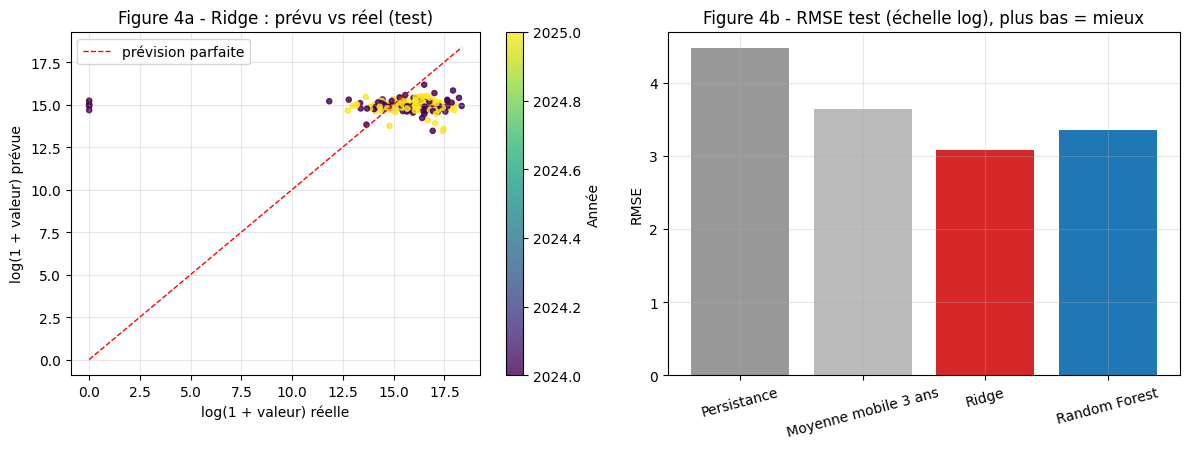

**Surapprentissage.** Ridge : RMSE 3.398 (entraînement) contre 3.188 (validation) ; forêt aléatoire : 2.847 contre 3.354. Un écart important entre entraînement et validation signale un début de surapprentissage. Écart validation - entraînement : +0.506 pour la forêt contre -0.210 pour Ridge.

In [45]:
# Figure 4 : résultats (valeurs prédites vs réelles sur le test + comparaison des RMSE)
p_te = pred[R][1]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
sc = axs[0].scatter(te["log_val"], p_te, c=te["annee"], cmap="viridis", s=14, alpha=0.8)
lim = [min(te["log_val"].min(), p_te.min()), max(te["log_val"].max(), p_te.max())]
axs[0].plot(lim, lim, "r--", lw=1, label="prévision parfaite")
axs[0].set(title="Figure 4a - Ridge : prévu vs réel (test)", xlabel="log(1 + valeur) réelle", ylabel="log(1 + valeur) prévue")
axs[0].legend(); fig.colorbar(sc, ax=axs[0], label="Année")
noms = list(resultats.index)
axs[1].bar(range(len(noms)), resultats["RMSE test (log)"], color=["#999999", "#bbbbbb", "#d62728", "#1f77b4"])
axs[1].set_xticks(range(len(noms))); axs[1].set_xticklabels([n.split(" (")[0] for n in noms], rotation=15)
axs[1].set(title="Figure 4b - RMSE test (échelle log), plus bas = mieux", ylabel="RMSE")
fig.tight_layout(); fig.savefig(FIG / "fig4_resultats.png", dpi=150); plt.show()

# Signes de surapprentissage : écart train / validation
rmse_tr = rmse(tr["log_val"], ridge_tr.predict(Xk(tr, K_R))); rmse_va = rmse(va["log_val"], ridge_tr.predict(Xk(va, K_R)))
rmse_tr_f = rmse(tr["log_val"], rf_tr.predict(Xk(tr, 3))); rmse_va_f = rmse(va["log_val"], rf_tr.predict(Xk(va, 3)))
md(f"""**Surapprentissage.** Ridge : RMSE {rmse_tr:.3f} (entraînement) contre {rmse_va:.3f} (validation) ; forêt aléatoire : {rmse_tr_f:.3f} contre {rmse_va_f:.3f}. {'Un écart important entre entraînement et validation signale un début de surapprentissage.' if (rmse_va-rmse_tr)>0.1 or (rmse_va_f-rmse_tr_f)>0.1 else 'Les écarts restent modérés : pas de surapprentissage marqué.'} Écart validation - entraînement : {rmse_va_f-rmse_tr_f:+.3f} pour la forêt contre {rmse_va-rmse_tr:+.3f} pour Ridge.""")

In [46]:
# Analyse des erreurs (Ridge, test)
te_e = te.copy(); te_e["prevu_log"] = p_te
te_e["prevu_usd"] = np.clip(np.expm1(te_e["prevu_log"]), 0, None)
te_e["err_abs_log"] = (te_e["log_val"] - te_e["prevu_log"]).abs()

print("Erreur moyenne (MAE log) par année de test :")
display(te_e.groupby("annee")["err_abs_log"].mean().round(3).to_frame("MAE log"))

pire = te_e.sort_values("err_abs_log", ascending=False).head(8)[["annee", "partenaire", "produit", "valeur", "prevu_usd", "err_abs_log"]]
pire = pire.assign(valeur=lambda x: x["valeur"].round(0), prevu_usd=lambda x: x["prevu_usd"].round(0), err_abs_log=lambda x: x["err_abs_log"].round(2))
print("Huit plus grosses erreurs (échelle log) :")
display(pire.reset_index(drop=True))

nuls = te_e["valeur"] == 0
top20 = te_e.sort_values("err_abs_log", ascending=False).head(20)
part_nuls20 = (top20["valeur"] == 0).mean()
mae_nul = te_e.loc[nuls, "err_abs_log"].mean() if nuls.any() else float("nan")
md(f"""**Analyse des erreurs.** Parmi les observations de test, {nuls.mean()*100:.1f} % ont une valeur exportée nulle ; parmi les 20 plus grosses erreurs, {part_nuls20*100:.0f} % concernent un flux nul. La MAE log est de {mae_nul:.2f} pour les flux nuls contre {te_e.loc[~nuls,'err_abs_log'].mean():.2f} pour les flux positifs. {'Les pires erreurs viennent donc surtout de flux qui apparaissent ou disparaissent : ce type de rupture (contrat, embargo, nouveau marché) est impossible à deviner à partir du seul passé du couple.' if part_nuls20 >= 0.5 else 'Les pires erreurs concernent surtout des flux positifs dont le niveau change fortement d\'une année à l\'autre (choc de prix ou de demande), que le seul passé du couple ne permet pas d\'anticiper.'}""")

# Illustration sur observations non vues : dernière année du test, plus gros flux
an_dern = te_e["annee"].max()
ill = te_e[te_e["annee"] == an_dern].sort_values("valeur", ascending=False).head(8)
ill = pd.DataFrame({"partenaire": ill["partenaire"], "produit": [nom_produit(c) for c in ill["produit"]],
                    "réel (M USD)": (ill["valeur"] / 1e6).round(1), "prévu Ridge (M USD)": (ill["prevu_usd"] / 1e6).round(1),
                    "écart relatif": ((ill["prevu_usd"] / ill["valeur"] - 1) * 100).round(0).astype(int).astype(str) + " %"})
print(f"Illustration : plus gros flux de {an_dern} (année non vue à l'entraînement ni à la validation)")
display(ill.reset_index(drop=True))

Erreur moyenne (MAE log) par année de test :


,MAE log
annee,
2024,2.121
2025,1.512


Huit plus grosses erreurs (échelle log) :


,annee,partenaire,produit,valeur,prevu_usd,err_abs_log
0,2025,Brazil,03,0.0,4111788.0,15.23
1,2024,Turkey,62,0.0,4089140.0,15.22
2,2024,India,87,0.0,3330777.0,15.02
3,2024,India,85,0.0,3105272.0,14.95
4,2024,Brazil,87,0.0,3050545.0,14.93
5,2024,Spain,07,0.0,2344643.0,14.67
6,2025,Spain,07,36958352.0,687965.0,3.98
7,2025,India,87,38472162.0,779084.0,3.90


**Analyse des erreurs.** Parmi les observations de test, 3.0 % ont une valeur exportée nulle ; parmi les 20 plus grosses erreurs, 30 % concernent un flux nul. La MAE log est de 15.00 pour les flux nuls contre 1.41 pour les flux positifs. Les pires erreurs concernent surtout des flux positifs dont le niveau change fortement d'une année à l'autre (choc de prix ou de demande), que le seul passé du couple ne permet pas d'anticiper.

Illustration : plus gros flux de 2025 (année non vue à l'entraînement ni à la validation)


,partenaire,produit,réel (M USD),prévu Ridge (M USD),écart relatif
0,Germany,74,65.5,2.3,-96 %
1,Brazil,31,64.6,3.2,-95 %
2,Brazil,85,53.3,3.0,-94 %
3,France,87,51.6,2.6,-95 %
4,France,85,43.1,3.0,-93 %
5,India,87,38.5,0.8,-98 %
6,Spain,07,37.0,0.7,-98 %
7,Spain,85,36.9,2.7,-93 %


## 8. Analyse critique
**Limites des données et de leur représentativité :** (i) le panel ne couvre que les 15 premiers partenaires et chapitres de la période d'entraînement (part de la valeur couverte affichée en section 4) ; (ii) les valeurs sont en USD **courants** : variations de prix, de change (dirham/euro/dollar) et volumes sont mélangés ; (iii) les données Comtrade sont déclaratives, révisables, et le dernier millésime peut être provisoire ; (iv) le niveau SH2 est agrégé : un chapitre regroupe des produits aux dynamiques très différentes ; (v) quelques années seulement sont disponibles pour le test, donc la conclusion repose sur peu de points dans le temps.

**Limites méthodologiques :** (i) le modèle ne contient aucune variable explicative externe (PIB des partenaires, taux de change, prix des matières premières, accords commerciaux, chocs comme 2020) ; (ii) la relation linéaire dans le log peut mal traiter les valeurs nulles ; (iii) les observations d'un même couple sont corrélées dans le temps, donc la validation sur deux années est une estimation bruitée ; (iv) un seul découpage chronologique est utilisé, faute de temps pour une validation glissante.

**Deux améliorations concrètes :** (1) ajouter des variables macro issues des autres sources de l'énoncé (Banque mondiale S5 : PIB et importations du partenaire ; FMI S8 : taux de change) et évaluer par validation glissante (*expanding window*) ; (2) passer en valeurs constantes (déflatées) ou séparer volumes et prix, et prévoir séparément les flux nuls (modèle en deux étapes : le flux existe-t-il, puis son niveau).

## 9. Conclusion

In [47]:
meilleur_test = resultats["RMSE test (log)"].idxmin()
if gain_te > 0 and gain_wape > 0:
    verdict = "Le modèle Ridge **fait mieux** que la persistance sur le test, selon le RMSE et selon le WAPE"
elif gain_te > 0:
    verdict = "Le modèle Ridge fait mieux que la persistance au RMSE log mais **pas au WAPE en USD** (résultat mitigé)"
elif gain_wape > 0:
    verdict = "Le modèle Ridge fait mieux que la persistance au WAPE en USD mais **pas au RMSE log** (résultat mitigé)"
else:
    verdict = "Le modèle Ridge **ne fait mieux que la persistance sur aucun des deux critères** du test"
md(f"""**Réponse explicite à la problématique.** {verdict} : RMSE log de {resultats.loc[R,'RMSE test (log)']:.3f} contre {resultats.loc[N,'RMSE test (log)']:.3f} pour la persistance (gain relatif {gain_te*100:+.1f} %), et WAPE de {resultats.loc[R,'WAPE test (USD)']*100:.1f} % contre {resultats.loc[N,'WAPE test (USD)']*100:.1f} % ({gain_wape*100:+.1f} %). Sur l'ensemble des méthodes, la plus précise au test est **{meilleur_test}**. La forêt aléatoire obtient un RMSE test de {resultats.loc[F,'RMSE test (log)']:.3f}.

**Objectif atteint ?** {'Oui' if objectif else 'Non'} : l'objectif annoncé (au moins 5 % de RMSE test en moins que la persistance, avec un WAPE plus faible) est {'atteint' if objectif else 'non atteint'}. {'' if objectif else 'Ce résultat reste informatif : la persistance est un adversaire exigeant sur des flux annuels, et les chocs de la période de test ne figurent pas dans le passé du couple. Les critères détaillés figurent dans le tableau de la section 7.'}

**Valeur commerciale / décisionnelle :** {'une prévision simple et interprétable, meilleure que « autant que cette année », peut servir à prioriser la prospection par pays et par chapitre et à anticiper les capacités logistiques ; son erreur typique reste cependant de l\'ordre de ' + f"{(np.exp(resultats.loc[R,'RMSE test (log)'])-1)*100:.0f} %" + ' par couple, ce qui impose de l\'utiliser comme ordre de grandeur et non comme engagement chiffré.' if objectif else 'le gain sur la persistance restant à démontrer sur les deux critères, il vaut mieux conserver la persistance (ou la moyenne mobile) comme prévision de référence et investir dans des variables explicatives externes avant de déployer un modèle plus complexe.'}""")

**Réponse explicite à la problématique.** Le modèle Ridge **fait mieux** que la persistance sur le test, selon le RMSE et selon le WAPE : RMSE log de 3.074 contre 4.474 pour la persistance (gain relatif +31.3 %), et WAPE de 84.0 % contre 100.3 % (+16.3 %). Sur l'ensemble des méthodes, la plus précise au test est **Ridge (modèle principal)**. La forêt aléatoire obtient un RMSE test de 3.356.

**Objectif atteint ?** Oui : l'objectif annoncé (au moins 5 % de RMSE test en moins que la persistance, avec un WAPE plus faible) est atteint. 

**Valeur commerciale / décisionnelle :** une prévision simple et interprétable, meilleure que « autant que cette année », peut servir à prioriser la prospection par pays et par chapitre et à anticiper les capacités logistiques ; son erreur typique reste cependant de l'ordre de 2063 % par couple, ce qui impose de l'utiliser comme ordre de grandeur et non comme engagement chiffré.